<a href="https://colab.research.google.com/github/rdsd/simpli_learn/blob/main/Image_Classification_on_Cifar10_data_using_CNN_v1_google_colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Image Classification on Cifar10 data using CNN


Objective:
----------
The goal of this demo is to build and train a Convolutional Neural Network (CNN)
to classify images from the CIFAR-10 dataset into 10 different categories
(e.g., airplane, automobile, bird, cat, deer, dog, frog, horse, ship, truck).

Data Explanation:
-----------------
The CIFAR-10 dataset is a well-known benchmark dataset for computer vision tasks.
- Total images: 60,000 color images of size 32x32 pixels.
- Training set: 50,000 images.
- Test set: 10,000 images.
- Number of classes: 10 (each image belongs to one of 10 categories).

Steps:
------
1. Load and preprocess the CIFAR-10 dataset.
2. Build a CNN model with convolutional, pooling, and fully connected layers.
3. Train the model using training data and validate on test data.
4. Evaluate performance on both training and test datasets.

In [ ]:
!pip install livelossplot

In [ ]:
# =========================
# Import Libraries
# =========================
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense, Flatten, Conv2D, MaxPooling2D
#from livelossplot import PlotLossesKerasTF
import matplotlib.pyplot as plt
from tensorflow.keras.layers import ZeroPadding2D
import numpy as np
import pandas as pd

In [ ]:
# =========================
# Load the data
# =========================
from tensorflow.keras.datasets import cifar10

(x_train, y_train), (x_test, y_test) = cifar10.load_data()

print("Training Data Shape:", x_train.shape)
print("Test Data Shape:", x_test.shape)

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 172s 1us/step
Training Data Shape: (50000, 32, 32, 3)
Test Data Shape: (10000, 32, 32, 3)


### Load CIFAR-10 Dataset from an Uploaded Local File
Instead of downloading the dataset from the internet every time, we can place your uploaded `cifar-10-python.tar.gz` file directly into Keras's cache directory.

In [ ]:
import os
import shutil
from tensorflow.keras.datasets import cifar10

# Path where you uploaded the file in Colab
uploaded_path = '/content/cifar-10-python.tar.gz'
# Path where Keras expects to find the cached file
keras_cache_dir = os.path.expanduser('~/.keras/datasets')

if os.path.exists(uploaded_path):
    # Create the cache directory if it doesn't exist
    os.makedirs(keras_cache_dir, exist_ok=True)

    # Move the file to the expected Keras directory
    shutil.copy(uploaded_path, os.path.join(keras_cache_dir, 'cifar-10-python.tar.gz'))
    print("Dataset successfully moved to Keras cache!")
else:
    print("Please upload 'cifar-10-python.tar.gz' to the /content/ folder first using the left file panel.")

# Load the dataset (this will now load instantly from the local cache)
(x_train, y_train), (x_test, y_test) = cifar10.load_data()
print("Training Data Shape:", x_train.shape)
print("Test Data Shape:", x_test.shape)

Dataset successfully moved to Keras cache!
Training Data Shape: (50000, 32, 32, 3)
Test Data Shape: (10000, 32, 32, 3)


In [ ]:
tr = y_train.flatten()
tr.ndim
print(tr)

[6 9 9 ... 9 1 1]


In [ ]:
print(pd.Series(tr).value_counts())

# 0: airplane
# 1: automobile
# 2: bird
# 3: cat
# 4: deer
# 5: dog
# 6: frog
# 7: horse
# 8: ship
# 9: truck

NameError: name 'pd' is not defined

In [ ]:
pd.Series(tr)[7]

np.uint8(7)

In [ ]:
x_train.ndim, x_test.ndim

(4, 4)

In [ ]:
print(x_train[0].ndim)

3


In [ ]:
print(x_train[0][:,:,0]) # (height, width, channels)-Red channel (RGB)

[[ 59  43  50 ... 158 152 148]
 [ 16   0  18 ... 123 119 122]
 [ 25  16  49 ... 118 120 109]
 ...
 [208 201 198 ... 160  56  53]
 [180 173 186 ... 184  97  83]
 [177 168 179 ... 216 151 123]]


In [ ]:
print(x_train[0][:,:,1]) # Green channel

[[ 62  46  48 ... 132 125 124]
 [ 20   0   8 ...  88  83  87]
 [ 24   7  27 ...  84  84  73]
 ...
 [170 153 161 ... 133  31  34]
 [139 123 144 ... 148  62  53]
 [144 129 142 ... 184 118  92]]


In [ ]:
print(x_train[0][:,:,2]) # Blue channel

[[ 63  45  43 ... 108 102 103]
 [ 20   0   0 ...  55  50  57]
 [ 21   0   8 ...  50  50  42]
 ...
 [ 96  34  26 ...  70   7  20]
 [ 96  42  30 ...  94  34  34]
 [116  94  87 ... 140  84  72]]


In [ ]:
print(x_train[0]/255) # Blue channel

[[[0.23137255 0.24313725 0.24705882]
  [0.16862745 0.18039216 0.17647059]
  [0.19607843 0.18823529 0.16862745]
  ...
  [0.61960784 0.51764706 0.42352941]
  [0.59607843 0.49019608 0.4       ]
  [0.58039216 0.48627451 0.40392157]]

 [[0.0627451  0.07843137 0.07843137]
  [0.         0.         0.        ]
  [0.07058824 0.03137255 0.        ]
  ...
  [0.48235294 0.34509804 0.21568627]
  [0.46666667 0.3254902  0.19607843]
  [0.47843137 0.34117647 0.22352941]]

 [[0.09803922 0.09411765 0.08235294]
  [0.0627451  0.02745098 0.        ]
  [0.19215686 0.10588235 0.03137255]
  ...
  [0.4627451  0.32941176 0.19607843]
  [0.47058824 0.32941176 0.19607843]
  [0.42745098 0.28627451 0.16470588]]

 ...

 [[0.81568627 0.66666667 0.37647059]
  [0.78823529 0.6        0.13333333]
  [0.77647059 0.63137255 0.10196078]
  ...
  [0.62745098 0.52156863 0.2745098 ]
  [0.21960784 0.12156863 0.02745098]
  [0.20784314 0.13333333 0.07843137]]

 [[0.70588235 0.54509804 0.37647059]
  [0.67843137 0.48235294 0.16470588]


In [ ]:
np.set_printoptions(threshold=100)  # limit output
print(x_train[0])

[[[ 59  62  63]
  [ 43  46  45]
  [ 50  48  43]
  ...
  [158 132 108]
  [152 125 102]
  [148 124 103]]

 [[ 16  20  20]
  [  0   0   0]
  [ 18   8   0]
  ...
  [123  88  55]
  [119  83  50]
  [122  87  57]]

 [[ 25  24  21]
  [ 16   7   0]
  [ 49  27   8]
  ...
  [118  84  50]
  [120  84  50]
  [109  73  42]]

 ...

 [[208 170  96]
  [201 153  34]
  [198 161  26]
  ...
  [160 133  70]
  [ 56  31   7]
  [ 53  34  20]]

 [[180 139  96]
  [173 123  42]
  [186 144  30]
  ...
  [184 148  94]
  [ 97  62  34]
  [ 83  53  34]]

 [[177 144 116]
  [168 129  94]
  [179 142  87]
  ...
  [216 184 140]
  [151 118  84]
  [123  92  72]]]


In [ ]:
print(x_train[7])

[[[ 28  35  39]
  [ 30  34  44]
  [ 33  44  47]
  ...
  [ 43  56  45]
  [ 52  64  53]
  [ 46  58  47]]

 [[ 27  30  38]
  [ 27  28  41]
  [ 21  31  39]
  ...
  [112 136  97]
  [117 140 101]
  [115 138 100]]

 [[ 34  36  42]
  [ 33  33  43]
  [ 24  30  40]
  ...
  [175 208 143]
  [177 209 144]
  [176 208 143]]

 ...

 [[142 176 118]
  [142 176 118]
  [150 184 127]
  ...
  [134 175 119]
  [128 168 112]
  [134 175 119]]

 [[140 176 124]
  [145 180 129]
  [150 186 134]
  ...
  [131 170 119]
  [130 170 119]
  [122 162 111]]

 [[134 171 123]
  [136 171 124]
  [136 171 124]
  ...
  [106 144 100]
  [104 142  99]
  [101 140  96]]]


In [ ]:
print(x_train[1])

[[[154 177 187]
  [126 137 136]
  [105 104  95]
  ...
  [ 91  95  71]
  [ 87  90  71]
  [ 79  81  70]]

 [[140 160 169]
  [145 153 154]
  [125 125 118]
  ...
  [ 96  99  78]
  [ 77  80  62]
  [ 71  73  61]]

 [[140 155 164]
  [139 146 149]
  [115 115 112]
  ...
  [ 79  82  64]
  [ 68  70  55]
  [ 67  69  55]]

 ...

 [[175 167 166]
  [156 154 160]
  [154 160 170]
  ...
  [ 42  34  36]
  [ 61  53  57]
  [ 93  83  91]]

 [[165 154 128]
  [156 152 130]
  [159 161 142]
  ...
  [103  93  96]
  [123 114 120]
  [131 121 131]]

 [[163 148 120]
  [158 148 122]
  [163 156 133]
  ...
  [143 133 139]
  [143 134 142]
  [143 133 144]]]


In [ ]:
# import tensorflow as tf

# # 1. Load and resize the image
# img_path = 'path_to_your_image.jpg'
# img = tf.keras.utils.load_img(img_path, target_size=(224, 224))

# # 2. Convert the image to a NumPy array (values 0-255)
# img_array = tf.keras.utils.img_to_array(img)

# # 3. Add a batch dimension (turns shape from 224x224x3 into 1x224x224x3)
# img_array = tf.expand_dims(img_array, 0)

# # 4. Normalize pixel values to be between 0 and 1
# img_array = img_array / 255.0

# print("TensorFlow Shape:", img_array.shape) # Output: (1, 224, 224, 3)


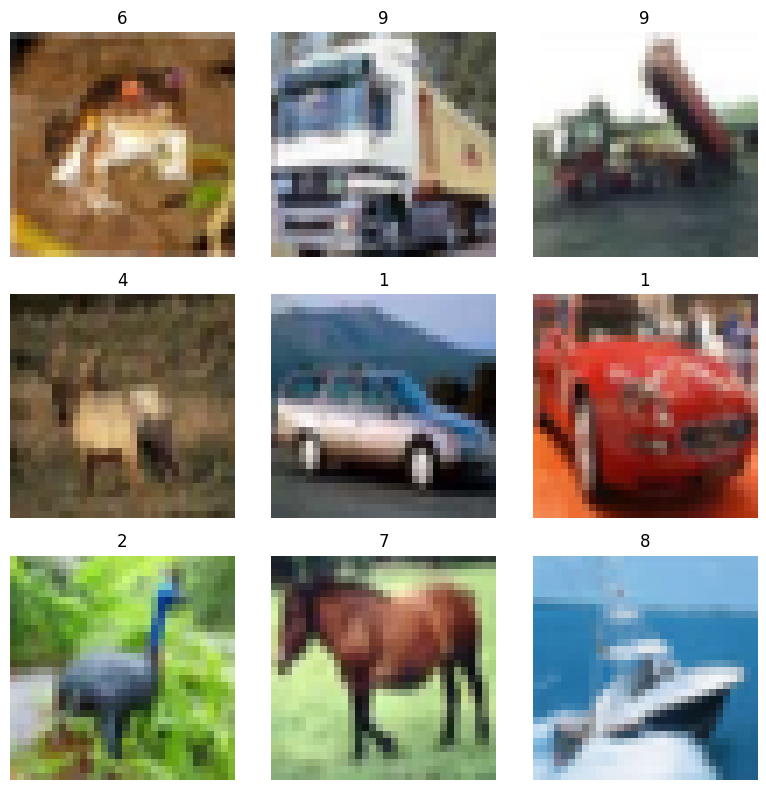

In [ ]:
plt.figure(figsize=(8,8))

for i in range(9):
    plt.subplot(3,3,i+1)
    plt.imshow(x_train[i])  ### 0-9
    plt.title(y_train[i][0])
    plt.axis("off")

plt.tight_layout()
plt.show()

The mapping of integer labels to their respective class names is as follows:

0: airplane

1: automobile

2: bird

3: cat

4: deer

5: dog

6: frog

7: horse

8: ship

9: truck

In [ ]:
y_train

array([[6],
       [9],
       [9],
       ...,
       [9],
       [1],
       [1]], dtype=uint8)

In [ ]:
# Normalize pixel values (scale between 0 and 1)
# x_train = x_train / 255.0
# x_test = x_test / 255.0

# 0 = black , 255 = white

In [ ]:
# =========================
# Define the CNN architecture
# =========================
model = Sequential()

# Input Layer
# Input shape = (32, 32, 3)
# 32 = height of image
# 32 = width of image
# 3  = number of channels (RGB image)
# This layer just defines the shape of input data.

model.add(Input(shape=(32, 32, 3)))


# ------------------------------
# First Convolution + Pooling Block
# ------------------------------

# Conv2D:
# 64  -> number of filters (kernels). So output depth = 64 feature maps.
# (3,3) -> kernel size (3x3 filter).
# activation='relu' -> applies ReLU after convolution (max(0,x)).
#
# What happens here:
# - Each of the 64 filters scans the image.
# - Each filter learns a different pattern (edges, textures, shapes).
# - Output becomes smaller spatially (since no padding specified → default = 'valid').
#
# Output size calculation (no padding, stride=1):
# (32 - 3 + 1) = 30
# So output shape becomes:
# (30, 30, 64)

# model.add(ZeroPadding2D(padding=2))   # adds 2 pixels on all sides - Manual padding
model.add(Conv2D(
    filters=64,
    kernel_size=(3,3),
    strides=(1,1),      #  stride
    padding='same',     # padding='valid' (NO padding is added) - auto padding inside convolution layer
    activation='relu'
))


# MaxPooling2D:
# pool_size=(2,2) means we take 2x2 regions.
# From each 2x2 block, maximum value is selected.
#
# This reduces spatial dimensions by half (if stride default = pool size).
#
# So:
# (30, 30, 64) → (15, 15, 64)
#
# Pooling reduces:
# - Computation
# - Overfitting
# - Spatial size

model.add(MaxPooling2D(pool_size=(2, 2)))


# ------------------------------
# Second Convolution + Pooling Block
# ------------------------------

# Conv2D with 32 filters
# Now input shape = (15, 15, 64)
#
# 32 filters → output depth = 32 feature maps.
# Kernel size = 3x3
#
# Output size:
# (15 - 3 + 1) = 13
# So output shape:
# (13, 13, 32)
#
# Note:
# Even though filters reduced from 64 → 32,
# this layer learns more complex patterns
# from the previous feature maps.

model.add(Conv2D(
    filters=32,
    kernel_size=(3, 3),
    strides=(1, 1),
    padding='same',
    activation='relu'
))


# MaxPooling again:
# (13, 13, 32) → divide spatial size by 2
#
# 13 / 2 = 6 (integer division in pooling)
#
# So output shape becomes:
# (6, 6, 32)

model.add(MaxPooling2D(pool_size=(2, 2)))


# ------------------------------
# Flatten Layer
# ------------------------------

# Flatten converts 3D tensor into 1D vector.
#
# Current shape:
# (6, 6, 32)
#
# Total neurons after flattening:
# 6 × 6 × 32 = 1152
#
# So output becomes:
# (1152,)
#
# This prepares data for Fully Connected layer.

model.add(Flatten())


# ------------------------------
# Fully Connected (Dense) Layers
# ------------------------------

# Dense(100):
# 100 neurons
# Each neuron connects to all 1152 inputs.
#
# Parameters in this layer:
# (1152 × 100) + 100 biases
#
# Activation = ReLU
# This layer combines extracted features to learn higher-level patterns.

model.add(Dense(100, activation='relu'))


# Final Output Layer
# Dense(10):
# 10 neurons → for 10 classes (e.g., digits 0-9 or CIFAR-10 classes)
#
# Activation = softmax
# Softmax converts outputs into probability distribution.
#
# Example output:
# [0.01, 0.05, 0.80, 0.02, ...]
#
# Highest probability → predicted class.
#
# Parameters:
# (100 × 10) + 10 biases

model.add(Dense(10, activation='softmax'))

In [ ]:
# =========================
# Define the CNN architecture
# =========================
model = Sequential()

# Input Layer
model.add(Input(shape=(32, 32, 3)))

# Convolution + Pooling Layers
model.add(Conv2D(filters=64, kernel_size=(3, 3), strides=(1, 1), padding='same',activation='relu'))
model.add(MaxPooling2D(pool_size=(2, 2)))

# Convolution + Pooling Layers
model.add(Conv2D(filters=128, kernel_size=(3, 3), strides=(1, 1), padding='same',activation='relu'))
model.add(MaxPooling2D(pool_size=(2, 2)))

model.add(Conv2D(filters=64, kernel_size=(3, 3), strides=(1, 1), padding='same',activation='relu'))
model.add(MaxPooling2D(pool_size=(2, 2)))

# Flatten and Fully Connected Layers
model.add(Flatten())
model.add(Dense(100, activation='relu'))
model.add(Dense(120, activation='relu'))
model.add(Dense(80, activation='relu'))
model.add(Dense(10, activation='softmax'))  # Output layer with 10 classes

In [ ]:
# =========================
# Compile the model
# =========================

# sparse_categorical_crossentropy is just categorical crossentropy where labels are given as class numbers instead of one-hot vectors.

model.compile(loss="sparse_categorical_crossentropy", optimizer="adam", metrics=['accuracy'])
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 64)     │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 8, 8, 64)       │        73,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 4, 4, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 100)            │       102,500 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 120)            │        12,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 80)             │         9,680 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │           810 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 274,550 (1.05 MB)

 Trainable params: 274,550 (1.05 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# @title Default title text
# =========================
# Train the model
# =========================

# batch_size = 32 means the model learns from 32 samples at a time before updating its weights, This is called Batch Gradient Descent.


history = model.fit(
    x_train, y_train,
    epochs=10,
    batch_size=32,
    validation_data=(x_test, y_test),
    callbacks=[PlotLossesKerasTF()]
)

Epoch 1/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 23s 9ms/step - accuracy: 0.4384 - loss: 1.5781 - val_accuracy: 0.5606 - val_loss: 1.2210
Epoch 2/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.5908 - loss: 1.1612 - val_accuracy: 0.6402 - val_loss: 1.0255
Epoch 3/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.6568 - loss: 0.9932 - val_accuracy: 0.6446 - val_loss: 1.0195
Epoch 4/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.6907 - loss: 0.8951 - val_accuracy: 0.6749 - val_loss: 0.9543
Epoch 5/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.7178 - loss: 0.8222 - val_accuracy: 0.6881 - val_loss: 0.9148
Epoch 6/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.7400 - loss: 0.7572 - val_accuracy: 0.7021 - val_loss: 0.8926
Epoch 7/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.7575 - loss: 0.7074 - val_accuracy: 0.6927 - val_loss: 0.9177
Epoch 8/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.7745 - loss: 0.6582 -

In [ ]:
from livelossplot import PlotLossesKerasTF

ModuleNotFoundError: No module named 'livelossplot'

In [ ]:
# =========================
# Evaluate Model on Train & Test
# =========================
train_loss, train_acc = model.evaluate(x_train, y_train, verbose=0)
test_loss, test_acc = model.evaluate(x_test, y_test, verbose=0)

print("\nModel Performance:")
print(f"Training Accuracy: {train_acc:.4f}, Training Loss: {train_loss:.4f}")
print(f"Test Accuracy: {test_acc:.4f}, Test Loss: {test_loss:.4f}")


Model Performance:
Training Accuracy: 0.8359, Training Loss: 0.4753
Test Accuracy: 0.7206, Test Loss: 0.8779


In [ ]:
y_train

array([[6],
       [9],
       [9],
       ...,
       [9],
       [1],
       [1]], dtype=uint8)

In [ ]:
y_train[0]

array([6], dtype=uint8)

In [ ]:
y_pred = model.predict(x_train)

1563/1563 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step


In [ ]:
y_pred

array([[5.95422462e-04, 2.02019888e-04, 4.35760915e-02, ...,
        5.66389458e-03, 2.04370925e-04, 2.89513904e-04],
       [3.22402866e-06, 6.52531253e-06, 9.43782030e-09, ...,
        1.90467482e-08, 1.79037301e-07, 9.99989986e-01],
       [1.91586949e-02, 3.67957284e-03, 3.01998248e-03, ...,
        1.93371475e-02, 3.37328925e-03, 8.91839445e-01],
       ...,
       [1.38540521e-01, 1.17700165e-02, 2.98189209e-03, ...,
        5.43456851e-03, 8.83890018e-02, 7.48830914e-01],
       [9.55282245e-04, 8.44314218e-01, 5.27621842e-06, ...,
        3.85176662e-07, 1.44188036e-03, 1.53281689e-01],
       [8.75646025e-02, 1.69899613e-01, 2.07399148e-02, ...,
        7.82558508e-03, 5.51016271e-01, 8.28124359e-02]], dtype=float32)

In [ ]:
y_pred[0].astype(float).round(2)

array([0.  , 0.  , 0.04, 0.37, 0.03, 0.31, 0.25, 0.01, 0.  , 0.  ])

In [ ]:
import numpy as np
np.argmax(y_pred[0])

np.int64(3)

### Use the Trained Model to Identify a Random Image
The following code selects a random image from the test set (`x_test`), runs it through the model, and displays the predicted label versus the true label.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Map of class names
class_names = {
    0: 'airplane',
    1: 'automobile',
    2: 'bird',
    3: 'cat',
    4: 'deer',
    5: 'dog',
    6: 'frog',
    7: 'horse',
    8: 'ship',
    9: 'truck'
}

# 1. Select a random index from the test set
random_idx = np.random.randint(0, len(x_test))
random_image = x_test[random_idx]
true_label_idx = y_test[random_idx][0]
true_label_name = class_names[true_label_idx]

# 2. Preprocess the image for prediction (add batch dimension: 1x32x32x3)
input_image = np.expand_dims(random_image, axis=0)

# 3. Make the prediction
predictions = model.predict(input_image)
predicted_label_idx = np.argmax(predictions[0])
predicted_label_name = class_names[predicted_label_idx]
confidence = predictions[0][predicted_label_idx] * 100

# 4. Plot the image and prediction results
plt.figure(figsize=(4, 4))
plt.imshow(random_image)
plt.title(f"Pred: {predicted_label_name} ({confidence:.1f}%)\nTrue: {true_label_name}",
          color='green' if predicted_label_idx == true_label_idx else 'red')
plt.axis('off')
plt.show()

NameError: name 'x_test' is not defined